# ¿Cuándo actuar? Sentimiento de las reseñas de Amazon de Serene Herbs Soursop Bitters
### Propuesta de un modelo de analítica de negocios · Trabajo final

**Curso:** Analítica de Negocios (CO0371), Escuela de Administración, EAFIT  |  **Profesor:** Juan Pablo Pérez  |  **Fecha:** 18 de noviembre de 2026

**Integrante:** Orlando Cardiles  |  **Código:** 1000263455  |  **Correo:** ojcardiles@eafit.edu.co

Este notebook se ejecuta **de principio a fin** (Entorno de ejecución → Ejecutar todo) con los datos del repositorio. Cada etapa tiene su celda de texto y la interpretación de cada resultado.

## 1. Problema de decisión

**Organización.** Una operación de analítica que construye una herramienta para ayudar a **vendedores de productos en Amazon** a leer lo que dicen sus compradores. Quien decide es el fundador de la operación (Orlando Cardiles), que define qué mide la herramienta y qué hace con sus alertas; el vendedor que la usa decide sobre su producto. El **caso piloto** es Serene Herbs Soursop Bitters + Black Seed Bitters (bundle de 32 oz, ASIN B0D4MPKGN6), una marca que es cliente de la operación: sus reseñas sirven de ejemplo y de datos para construir y probar el modelo, pero el producto de este trabajo es la herramienta y no la marca.

**Decisión.** Dos decisiones concretas a partir de lo que dicen los compradores en sus reseñas, y no solo de cuántas estrellas dan: (a) **cuándo revisar el lote o al proveedor**, cuando suben las quejas (por ejemplo, "fórmula aguada" o "plástico"); (b) **a qué clientes responder o reembolsar**, es decir, qué reseñas negativas atender primero.

**Cómo se decide hoy.** Con el promedio de estrellas y leyendo reseñas sueltas, que es lo que la herramienta hace hoy; ninguna de las dos formas mide a tiempo el cambio de ánimo de los compradores ni escala a cientos de reseñas.

**Por qué importa el sentimiento y su evolución.** La estrella resume, pero el texto explica. En esta base el porcentaje de reseñas de 4-5★ pasó de 30 % en 2025-S1 a 73 % en 2026-S2: un cambio grande que un promedio tarda en mostrar y que no dice qué lo provocó. Leer a mano las 1.271 reseñas no escala; un modelo que lea el sentimiento del texto permite vigilar cada mes y reaccionar a tiempo cuando baja.

**Qué cuesta equivocarse.** Hay dos errores con costos distintos: (a) leer como elogio una queja (*falso positivo*) deja pasar un problema que nadie atiende; (b) leer como queja un elogio (*falso negativo*) genera una falsa alarma y tiempo perdido. **El error más caro es el primero (falso positivo):** una queja leída como elogio no se atiende y cuesta reputación y tiempo; la falsa alarma cuesta solo tiempo de revisión. El costo no se estimó en dinero: es un juicio de quien decide, no una medición. Esa respuesta decide qué métrica se mira primero (ver §3).

## 2. Preparación del entorno y de los datos

In [1]:
import os, sys, subprocess, importlib.util, warnings
warnings.filterwarnings('ignore')
REPO_URL = 'https://github.com/ocardiles03/resenas-nlp-trabajo-final'   # repositorio publico: se clona sin token
if not os.path.exists('src/acierto_sentimiento.py'):
    if not REPO_URL:
        raise SystemExit('Falta REPO_URL: pega arriba la URL del repositorio.')
    url = REPO_URL
    if 'google.colab' in sys.modules and url.startswith('https://') and '@' not in url:   # si el repositorio fuera privado: token en los Secretos de Colab (clave GITHUB_TOKEN)
        try:
            from google.colab import userdata
            url = url.replace('https://', 'https://' + userdata.get('GITHUB_TOKEN') + '@', 1)
        except Exception:
            pass   # sin token: se intenta clonar tal cual (repositorio publico)
    subprocess.run(['git', 'clone', '--depth', '1', url, 'repo'], check=True)
    os.chdir('repo')
if 'google.colab' in sys.modules:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'scikit-learn', 'openpyxl'], check=True)
print('Carpeta de trabajo:', os.getcwd())

Carpeta de trabajo: /Users/car/Proyecto_Resenas_NLP


In [2]:
from collections import Counter
spec = importlib.util.spec_from_file_location('acierto_sentimiento', 'src/acierto_sentimiento.py')
ac = importlib.util.module_from_spec(spec); sys.modules['acierto_sentimiento'] = ac; spec.loader.exec_module(ac)
try:
    from IPython.display import Markdown, display
    def mostrar(txt): display(Markdown(txt))
except ImportError:
    def mostrar(txt): print(txt)

### 2.1 Corpus completo (datos originales: Excel v4)

In [3]:
corpus = ac.dc.cargar(ac.dc.XLSX)
fechas = sorted(r['fecha'] for r in corpus)
print(f"Reseñas con texto y fecha: {len(corpus)}")
print(f"Periodo: {fechas[0]} a {fechas[-1]}")
print("Distribución por estrellas:", dict(sorted(Counter(r['estrellas'] for r in corpus).items())))

Reseñas con texto y fecha: 1271
Periodo: 2024-06-07 a 2026-10-21
Distribución por estrellas: {1: 342, 2: 102, 3: 99, 4: 120, 5: 608}


#### Preparación del corpus: de la hoja original al corpus analizado (solo conteos)

In [4]:
from openpyxl import load_workbook
hoja = list(load_workbook(ac.dc.XLSX, read_only=True)['Reseñas'].iter_rows(values_only=True))
cab = hoja[0]; crudas = [dict(zip(cab, v)) for v in hoja[1:] if any(v)]
ids = [x['ID reseña'] for x in crudas if x['ID reseña']]
sin_texto = [x for x in crudas if not (x['Reseña'] or '').strip()]
print(f"Filas en la hoja original:              {len(crudas)}")
print(f"  sin ID de reseña:                     {sum(1 for x in crudas if not x['ID reseña'])}")
print(f"  ID repetido (se conserva la primera): {len(ids) - len(set(ids))}")
print(f"  sin texto de reseña (se descartan):   {len(sin_texto)}")
print(f"Corpus analizado:                       {len(corpus)}")
print(f"  sin fecha:                            {sum(1 for r in corpus if not r['fecha'])}")
print(f"  de 3 estrellas (en el corpus, pero fuera del entrenamiento del léxico y de los clasificadores): {sum(1 for r in corpus if r['estrellas'] == 3)}")

Filas en la hoja original:              1276
  sin ID de reseña:                     0
  ID repetido (se conserva la primera): 0
  sin texto de reseña (se descartan):   5
Corpus analizado:                       1271
  sin fecha:                            0
  de 3 estrellas (en el corpus, pero fuera del entrenamiento del léxico y de los clasificadores): 99


#### Base preparada (`data/base_preparada_resenas.csv`, creada con `src/preparar_base.py`)

In [5]:
import csv
with open(ac.DATA / 'base_preparada_resenas.csv', encoding='utf-8', newline='') as fh:
    prep = list(csv.DictReader(fh))
print(f"Base preparada: {len(prep)} reseñas; columnas: {list(prep[0])}")
print("Reseñas por semestre:", dict(sorted(Counter(x['semestre'] for x in prep).items())))
print("Clase según estrellas:", dict(Counter(x['clase_estrellas'] for x in prep)))
largos = sorted(len(x['texto'].split()) for x in prep)
print(f"Palabras por reseña: mediana {largos[len(largos) // 2]}, mínimo {largos[0]}, máximo {largos[-1]}")
print(f"Compra verificada: {sum(1 for x in prep if x['compra_verificada'] == 'Sí')} de {len(prep)}")

Base preparada: 1271 reseñas; columnas: ['id', 'fecha', 'semestre', 'estrellas', 'clase_estrellas', 'titulo', 'texto', 'compra_verificada', 'enlace']
Reseñas por semestre: {'2024-S1': 2, '2024-S2': 90, '2025-S1': 268, '2025-S2': 324, '2026-S1': 313, '2026-S2': 274}
Clase según estrellas: {'Positivo': 728, 'Negativo': 444, 'Tibia': 99}
Palabras por reseña: mediana 24, mínimo 1, máximo 600
Compra verificada: 1206 de 1271


**Decisiones de preparación (y por qué).**

- Se descartan las filas sin texto (5) porque no hay nada que leer; no hay IDs repetidos ni fechas faltantes.
- Se agrega `semestre` (AAAA-S1/S2) para describir la evolución con grupos de tamaño razonable; por mes habría pocas reseñas en 2024.
- Se agrega `clase_estrellas`: Positivo (4-5★) y Negativo (1-2★). Las de 3★ (99) no son claramente ni una ni otra y quedan fuera del entrenamiento.
- Se quita `Reviewer` (nombre de una persona): no hace falta para el análisis y es dato personal.
- **No se corrigen atípicos ni faltantes numéricos:** las estrellas solo toman valores 1-5 y no hay datos faltantes en las variables usadas.
- El texto se pasa a minúsculas, se lematiza y se quitan palabras vacías, **conservando** *no*, *not*, *never* y las palabras de opinión (porque cambian el sentido). No hay escalamiento de variables numéricas: los modelos de texto usan TF-IDF, que ya normaliza los pesos de las palabras.

#### Diccionario de variables

| Variable | Descripción | Tipo | Unidad | Rol |
|---|---|---|---|---|
| `id` | Identificador de la reseña en Amazon | Texto | — | Identificador |
| `fecha` | Fecha de publicación de la reseña | Fecha (ISO) | Día | Perfilamiento (origen de `semestre`) |
| `semestre` | Semestre de la fecha (AAAA-S1 / AAAA-S2) | Categórica ordinal | Semestre | Perfilamiento (evolución en el tiempo) |
| `estrellas` | Calificación que dio el comprador (1 a 5) | Numérica discreta | Estrellas | Variable numérica pronosticable (no se pronostica aquí), fuente de la etiqueta de clasificación y variable de perfilamiento de los grupos |
| `clase_estrellas` | Positivo (4-5★), Negativo (1-2★) o Tibia (3★) | Categórica | — | Objetivo de clasificación (KNN y Naive Bayes) |
| `titulo`, `texto` | Título y texto de la reseña (inglés) | Texto | — | Variables explicativas (entran al léxico, KNN y Naive Bayes) y variable de agrupamiento (k-means) |
| `compra_verificada` | Si Amazon verificó la compra (Sí/No) | Categórica | — | Perfilamiento (de los grupos) |
| `enlace` | URL de la reseña en Amazon | Texto | — | Trazabilidad (no entra al modelo) |
| `sentimiento_manual` | Positivo / Negativo / Neutro según lectura humana (solo en la muestra etiquetada) | Categórica | — | Referencia para medir el acierto (objetivo de clasificación) |

#### Descripción de los datos

- **Qué es un registro:** una reseña de un comprador en Amazon.com del bundle B0D4MPKGN6, con título, texto en inglés, estrellas, fecha, enlace y marca de compra verificada.
- **Tamaño y periodo:** 1.271 reseñas con texto, del 2024-06-07 al 2026-10-21 (unos 2,4 años). Por estrellas: 1★ = 342, 2★ = 102, 3★ = 99, 4★ = 120, 5★ = 608. Compra verificada: 1206 de 1271. Mediana de 24 palabras por reseña.
- **Procedencia:** ficha completa en `data/README_datos.md`. Las reseñas se recolectaron en octubre de 2026 con el navegador (Chrome) y con la herramienta Apify; los datos originales tal como se descargaron están en `data/crudo_chrome_apify/` y `data/bundle_xlsx_historico/`. Los recolectó Orlando Cardiles con las dos herramientas. Lotes (fecha del archivo): Apify, 23 de octubre de 2026 (`dataset_amazon-reviews-scraper-with-advanced-filters_2026-10-23_...json`); Chrome, 23, 24 y 25 de octubre de 2026 (`serene_chrome_reviews.json`, `_v2` y `_v3`; las fechas de los tres son las de modificación del archivo). Enlace: `https://www.amazon.com/product-reviews/B0D4MPKGN6/`.
- **Limitaciones:** (1) un solo producto y un solo canal; (2) solo reseñas con texto, y quien reseña no es el comprador promedio; (3) Amazon entrega ~10 reseñas por vista de filtro, así que se descargaron filtrando por estrellas y palabras: la proporción de estrellas de la base puede no ser la de la página; (4) todo está en inglés; (5) el periodo cubre unos 2,4 años (el profesor aprobó usarlo): con tan poco tiempo no se pueden estimar patrones de largo plazo como la estacionalidad.

### 2.2 Muestra etiquetada a mano (referencia para medir el acierto)

In [6]:
# La hoja de 100 es obligatoria. Las hojas de ampliación se suman SOLO si ya están etiquetadas por completo.
filas, hojas, avisos = ac.hojas_etiquetadas()
for a in avisos: print(a)
print('Hojas usadas:', hojas)
print(f"Reseñas etiquetadas a mano: {len(filas)}")
print(dict(Counter(r['manual'] for r in filas)))

(se omite etiquetado_manual_ampliacion_200.xlsx: 200 reseñas sin etiquetar)
(se omite etiquetado_manual_soursop_200.xlsx: 200 reseñas sin etiquetar)
Hojas usadas: ['etiquetado_manual_100.xlsx']
Reseñas etiquetadas a mano: 100
{'Positivo': 52, 'Negativo': 33, 'Neutro': 15}


**La muestra manual.**

- **Cómo se eligió:** 100 reseñas aleatorias estratificadas por estrellas (`docs/PLAN_base_resenas.md`, `data/validacion_100.csv`). La hoja de etiquetado (`src/hoja_etiquetado.py`) solo muestra título y texto: quien etiquetó **no vio** las estrellas ni la lectura del léxico. Como el estrato es la nota y no el semestre, algunos semestres quedan con muy pocas reseñas (ver §4.6).
- **Quién etiquetó y con qué criterio:** Orlando Cardiles, a mano, leyendo solo el texto (no las estrellas). **Positivo:** el texto muestra satisfacción clara o intención de recompra. **Negativo:** la persona dice que algo falló o que no volverá a comprar (por ejemplo, "me sirvió la vez pasada pero este no me gusta igual"). **Neutro:** mixto o provisional (por ejemplo, "me sirvió el primero y estoy probando el segundo"). Resultado: Positivo 52, Negativo 33, Neutro 15.
- **Neutro y las métricas:** las 15 reseñas Neutro **no entran** en las métricas binarias (Positivo contra Negativo); quedan 85. Sí aparecen en la matriz de 3 clases (§4.4).
- **Limpieza de la muestra:** 4 textos de la hoja traen avisos de la interfaz de Amazon ("No se pudo cargar el archivo multimedia", "Haz clic para reproducir el video"); `leer_hojas` los quita antes de medir.

## 3. Modelos: léxico, KNN, Naive Bayes y k-means

| Modelo | Familia del curso | Qué lee del texto |
|---|---|---|
| **Léxico del proyecto** (`data/lexico_cliente_v4.json`) | Análisis de texto y sentimientos | Una "balanza": cada palabra suma o resta y el signo del total da la lectura |
| **KNN** (TF-IDF, distancia coseno) | Clasificación | Busca las *k* reseñas más parecidas y toma su voto |
| **Naive Bayes** (TF-IDF) | Clasificación | Qué tan típica es cada palabra de las reseñas positivas y de las negativas |
| **k-means** (TF-IDF + SVD) | Agrupamiento | Qué reseñas hablan de lo mismo, sin usar estrellas ni etiquetas |

Son **cuatro modelos de tres familias distintas** (el enunciado exige al menos dos): los tres primeros miden el sentimiento y el cuarto descubre de qué se habla.

**Cómo funciona cada uno, sin fórmulas.**

- *Léxico.* Las palabras y sus pesos se aprenden de reseñas de este mismo tipo (Amazon, inglés, producto de salud): una palabra pesa +2 si el 75 % o más de sus apariciones está en reseñas de 4-5★ y -2 si el 25 % o menos (mínimo 15 apariciones en 10 reseñas), lo que da 104 palabras positivas y 78 negativas. Una negación (*no, not, never*) invierte las tres palabras siguientes. Si el total es mayor que 0 la lectura es Positivo, menor que 0 Negativo, y 0 Neutro. **Por qué es el adecuado para este idioma y tipo de texto:** un léxico general no conoce el vocabulario del producto; el aprendido de estas reseñas sí: *bloated* o *cleanse*, que suenan mal, están del lado positivo porque los compradores contentos cuentan que quedaron "menos hinchados" o que "limpió" su cuerpo.
- *KNN.* Cada reseña se convierte en números según qué palabras y parejas de palabras usa (TF-IDF: pesa más lo raro y específico que lo común). Para leer una reseña nueva se buscan las *k* más parecidas (por ángulo, distancia coseno) y se mira cuántas fueron positivas. Se descarta mirar solo una (*k* = 1) porque cualquier rareza la desvía.
- *Naive Bayes.* Cuenta qué tan frecuente es cada palabra en las reseñas positivas y en las negativas y combina esas frecuencias asumiendo que las palabras no se influyen entre sí (por eso "ingenuo"). El parámetro alfa es un suavizado para que una palabra vista una sola vez no decida todo.
- *k-means.* Resume cada reseña en 30 números (los ejes de temas que más separan los textos, con una descomposición SVD del TF-IDF) y reparte las reseñas en *k* grupos moviendo los centros hasta que cada reseña quede con el centro que más se le parece. **Por qué se ajusta al problema:** no necesita etiquetas ni estrellas, así que muestra de qué hablan los compradores con independencia del sentimiento, que es lo que hace falta para decidir si revisar el lote (§1). El número de grupos se escoge con silueta, codo y estabilidad (§4.10).
- *Alternativas descartadas.* Redes neuronales o modelos de lenguaje preentrenados: no se vieron en el curso y serían difíciles de explicar a un gerente. La regresión logística sobre TF-IDF se probó (`docs/comparacion_modelos_v4.md`, exactitud 0.915) y rinde igual que KNN, así que no aporta una conclusión distinta.

**Configuración.** Partición 80/20 **estratificada** con semilla fija (42). El parámetro principal (*k* en KNN, alfa en Naive Bayes) se escoge con **validación cruzada de 5 pliegues solo sobre el 80 % de entrenamiento**, con el AUC como criterio. Se hacen dos pruebas:

- **Prueba A (estrellas como etiqueta):** 1172 reseñas polares (4-5★ contra 1-2★), 937 de entrenamiento y 235 de prueba. Mide a los tres modelos sobre las mismas reseñas.
- **Prueba B (muestra manual):** las 100 reseñas etiquetadas a mano, 80 de entrenamiento y 20 de prueba (17 sin Neutro). Es la referencia "de verdad" pero es pequeña.

**Métricas.** Se reportan matriz de confusión, exactitud (con intervalo de confianza), sensibilidad (positivas bien leídas), especificidad (negativas bien leídas), precisión (de lo que el modelo llama elogio, cuánto lo es) y F1 y AUC. Para el cliente importa sobre todo la **especificidad y la precisión**: son las que miden las quejas que se escapan leídas como elogio; la sensibilidad mide las falsas alarmas. Esa elección sale del juicio de quien decide (§1): el error más caro es dejar pasar una queja.

In [7]:
# Prueba A: las estrellas como etiqueta, partición 80/20 estratificada, k y alfa por validación cruzada solo en el 80 %.
e = ac.evaluar_estrellas(corpus)
print(f"Prueba A: {e['n']} reseñas polares -> entrenamiento {e['n_train']}, prueba {e['n_test']} ({e['pos_test']} positivas)")
print(f"k elegido (KNN): {e['k']}   |   alfa elegido (Naive Bayes): {e['alfa']}   |   corte = {e['corte']:.3f} (proporción de positivas del entrenamiento)")
mostrar('| k | ' + ' | '.join(map(str, e['aucs_k'])) + ' |\n|---|' + '---|' * len(e['aucs_k']) +
        '\n| AUC (CV), KNN | ' + ' | '.join(ac.f(v) for v in e['aucs_k'].values()) + ' |')
mostrar('| alfa | ' + ' | '.join(map(str, e['aucs_alfa'])) + ' |\n|---|' + '---|' * len(e['aucs_alfa']) +
        '\n| AUC (CV), Naive Bayes | ' + ' | '.join(ac.f(v) for v in e['aucs_alfa'].values()) + ' |')

Prueba A: 1172 reseñas polares -> entrenamiento 937, prueba 235 (146 positivas)
k elegido (KNN): 21   |   alfa elegido (Naive Bayes): 0.1   |   corte = 0.621 (proporción de positivas del entrenamiento)


| k | 1 | 3 | 5 | 7 | 9 | 11 | 15 | 21 | 25 | 31 | 41 | 51 | 101 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| AUC (CV), KNN | 0.814 | 0.914 | 0.931 | 0.942 | 0.947 | 0.947 | 0.951 | 0.952 | 0.951 | 0.949 | 0.949 | 0.949 | 0.949 |

| alfa | 0.1 | 0.3 | 1.0 | 3.0 |
|---|---|---|---|---|
| AUC (CV), Naive Bayes | 0.958 | 0.958 | 0.957 | 0.956 |

In [8]:
# Prueba B: la muestra manual.
r = ac.evaluar(filas, corpus)
print(f"Partición 80/20 (semilla {ac.SEMILLA}): entrenamiento {r['n_train']}, prueba {r['n_test']} ({r['n_test_bin']} sin Neutro)")
print(f"k elegido (KNN manual): {r['k_manual']}   |   k elegido (KNN estrellas): {r['k_estrellas']}   |   alfa (Naive Bayes): {r['alfa_nb']}")
mostrar('| k | ' + ' | '.join(map(str, r['aucs_manual'])) + ' |\n|---|' + '---|' * len(r['aucs_manual']) +
        '\n| AUC (CV), KNN manual | ' + ' | '.join(ac.f(v) for v in r['aucs_manual'].values()) + ' |')

Partición 80/20 (semilla 42): entrenamiento 80, prueba 20 (17 sin Neutro)
k elegido (KNN manual): 11   |   k elegido (KNN estrellas): 25   |   alfa (Naive Bayes): 0.3


| k | 1 | 3 | 5 | 7 | 9 | 11 | 15 | 21 | 25 | 31 | 41 | 51 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| AUC (CV), KNN manual | 0.814 | 0.911 | 0.942 | 0.953 | 0.951 | 0.973 | 0.944 | 0.908 | 0.916 | 0.889 | 0.789 | 0.641 |

**Por qué ese *k* y ese alfa.** En la prueba A el AUC de validación cruzada sube de 0.814 con *k* = 1 hasta 0.952 con *k* = 21 y se mantiene casi plano (≥ 0.949) entre 15 y 101: pocos vecinos se dejan engañar por una reseña rara y muchísimos pierden la señal; se toma el máximo (*k* = 21). Para Naive Bayes los cuatro alfas dan un AUC casi idéntico (0.956 a 0.958); gana alfa = 0.1, así que el suavizado casi no importa en este corpus. En la muestra manual, con solo 80 reseñas de entrenamiento, el *k* elegido es 11 y la curva es mucho más sensible: es otra señal de que esa muestra es chica.

## 4. Resultados

### 4.1 Prueba A: tres modelos sobre las mismas 235 reseñas de prueba (etiqueta = estrellas)

In [9]:
mostrar('\n'.join(ac.tabla_metricas(e['prueba'])))

| Modelo | n | VN | FP | FN | VP | Exactitud (IC 95 %) | Sensibilidad | Especificidad | Precision | F1 | AUC |
|---|---|---|---|---|---|---|---|---|---|---|---|
| Lexico (aprendido con el 80 %) | 235 | 77 | 12 | 24 | 122 | 0.847 (0.795-0.887) | 0.836 | 0.865 | 0.910 | 0.871 | 0.939 |
| KNN | 235 | 83 | 6 | 15 | 131 | 0.911 (0.867-0.941) | 0.897 | 0.933 | 0.956 | 0.926 | 0.968 |
| Naive Bayes | 235 | 81 | 8 | 14 | 132 | 0.906 (0.862-0.937) | 0.904 | 0.910 | 0.943 | 0.923 | 0.976 |

**Lectura.** Con 235 reseñas de prueba (más de diez veces las de la muestra manual), KNN acierta 0.911 (IC 95 %: 0.867-0.941), Naive Bayes 0.906 (IC 95 %: 0.862-0.937) y el léxico 0.847 (IC 95 %: 0.795-0.887). KNN y Naive Bayes son prácticamente equivalentes (su cantidad de aciertos difiere en 1 reseña(s) de 235). El léxico queda 6.4 puntos por debajo de KNN y los intervalos apenas se tocan (el de KNN empieza en 0.867; el del léxico termina en 0.887): la ventaja de los clasificadores existe, pero es moderada, no abrumadora.

**Tipo de error.** El léxico deja pasar **12** quejas leídas como elogio (falsos positivos) y confunde **24** elogios con quejas o con texto sin veredicto (falsos negativos); KNN comete 6 y 15, y Naive Bayes 8 y 14. Si lo caro es perder una queja, KNN es el mejor de los tres (mayor especificidad, 0.933, y precisión, 0.956); el léxico deja escapar casi el doble de quejas.

**AUC.** Los tres están sobre 0.939: si se toman al azar una reseña positiva y una negativa, el modelo pone la positiva por encima casi siempre. Es decir, ordenan bien las reseñas aunque su exactitud sea distinta.

**Advertencia.** La "verdad" de esta prueba es la nota en estrellas, no una lectura humana del texto: una reseña de 5★ que se queja en el texto cuenta como error del modelo aunque el modelo tenga razón. Por eso se complementa con la muestra manual (§4.2-4.3).

### 4.2 Prueba B: muestra manual, conjunto de prueba (20 %)

In [10]:
mostrar('\n'.join(ac.tabla_metricas(r['prueba'])))

| Modelo | n | VN | FP | FN | VP | Exactitud (IC 95 %) | Sensibilidad | Especificidad | Precision | F1 | AUC |
|---|---|---|---|---|---|---|---|---|---|---|---|
| Lexico del proyecto | 17 | 7 | 0 | 1 | 9 | 0.941 (0.730-0.990) | 0.900 | 1.000 | 1.000 | 0.947 | 1.000 |
| Lexico sin la muestra | 17 | 7 | 0 | 1 | 9 | 0.941 (0.730-0.990) | 0.900 | 1.000 | 1.000 | 0.947 | 0.986 |
| KNN con estrellas | 17 | 5 | 2 | 0 | 10 | 0.882 (0.657-0.967) | 1.000 | 0.714 | 0.833 | 0.909 | 0.993 |
| Naive Bayes con estrellas | 17 | 5 | 2 | 0 | 10 | 0.882 (0.657-0.967) | 1.000 | 0.714 | 0.833 | 0.909 | 1.000 |
| KNN con etiquetas manuales | 17 | 7 | 0 | 2 | 8 | 0.882 (0.657-0.967) | 0.800 | 1.000 | 1.000 | 0.889 | 0.986 |

**Lectura.** La prueba tiene solo 17 reseñas (sin Neutro). Los modelos aciertan 0.882 a 0.941, es decir, se diferencian por una o dos reseñas, y los intervalos de confianza (de 26 a 31 puntos de ancho) se solapan casi por completo. **Con esta muestra no se puede declarar un ganador**; sirve para comprobar que los modelos hacen algo razonable, no para ordenarlos. El KNN entrenado con etiquetas manuales aprendió de solo 80 reseñas, por eso es el menos estable.

### 4.3 Prueba B: toda la muestra etiquetada (modelos que no se entrenan con ella)

In [11]:
mostrar('\n'.join(ac.tabla_metricas(r['todas'])))

| Modelo | n | VN | FP | FN | VP | Exactitud (IC 95 %) | Sensibilidad | Especificidad | Precision | F1 | AUC |
|---|---|---|---|---|---|---|---|---|---|---|---|
| Lexico del proyecto | 85 | 32 | 1 | 4 | 48 | 0.941 (0.870-0.975) | 0.923 | 0.970 | 0.980 | 0.950 | 0.987 |
| Lexico sin la muestra | 85 | 31 | 2 | 4 | 48 | 0.929 (0.854-0.967) | 0.923 | 0.939 | 0.960 | 0.941 | 0.976 |
| KNN con estrellas | 85 | 29 | 4 | 1 | 51 | 0.941 (0.870-0.975) | 0.981 | 0.879 | 0.927 | 0.953 | 0.991 |
| Naive Bayes con estrellas | 85 | 28 | 5 | 1 | 51 | 0.929 (0.854-0.967) | 0.981 | 0.848 | 0.911 | 0.944 | 0.994 |

In [12]:
# ¿La nota en estrellas coincide con lo que leyó una persona? (solo reseñas no Neutro y no de 3★)
est = {x['id']: x['estrellas'] for x in corpus}
ok = tot = 0
for x in filas:
    if est.get(x['id'], 3) == 3 or x['manual'] == 'Neutro':
        continue
    tot += 1; ok += int((est[x['id']] >= 4) == (x['manual'] == 'Positivo'))
print(f"La nota coincide con la etiqueta manual en {ok} de {tot} reseñas ({ok / tot:.1%}); quedan fuera {len(filas) - tot} (Neutro, 3★ o sin nota)")

La nota coincide con la etiqueta manual en 79 de 82 reseñas (96.3%); quedan fuera 18 (Neutro, 3★ o sin nota)


**Lectura.** Sobre las 85 reseñas no Neutro, el léxico acierta 0.941 (IC 95 %: 0.870-0.975) y KNN con estrellas 0.941 (IC 95 %: 0.870-0.975). El **léxico sin la muestra** (aprendido sin esas reseñas) acierta 0.929 (IC 95 %: 0.854-0.967): casi igual, así que el buen resultado **no** se debe a que el léxico "haya visto" la muestra. La nota coincide con la lectura humana en 79 de 82 reseñas (96.3%), por eso las estrellas son una buena aproximación a la etiqueta manual en la muestra. El léxico acierta menos en la prueba A (0.847) que aquí (0.929); con solo 85 reseñas la diferencia no se puede atribuir con seguridad a nada, y es una razón más para ampliar la muestra manual.

### 4.4 Matriz de 3 clases del léxico (filas = manual, columnas = léxico)

In [13]:
mostrar('| manual \\ léxico | ' + ' | '.join(r['etq3']) + ' |\n|---|---|---|---|\n' +
        '\n'.join(f'| {e_} | ' + ' | '.join(str(int(v)) for v in fila) + ' |' for e_, fila in zip(r['etq3'], r['m3'])))

| manual \ léxico | Negativo | Neutro | Positivo |
|---|---|---|---|
| Negativo | 29 | 3 | 1 |
| Neutro | 9 | 2 | 4 |
| Positivo | 0 | 4 | 48 |

**Lectura.** El léxico lee bien los extremos (48 de 52 positivas y 29 de 33 negativas), pero casi nunca acierta un Neutro (2 de 15): 9 los lee como Negativo. La razón se ve en los casos (§4.5): las reseñas Neutro suelen mezclar una queja con algo bueno, y la balanza suma la queja.

### 4.5 Reseñas donde el léxico no coincide con la etiqueta manual

In [14]:
import json
lex = ac.lexico_proyecto()
casos = []
for x in filas:
    p = ac.lx.puntaje(x['titulo'] + '. ' + x['texto'], lex)
    lectura = ac.lectura_lexico(p)
    if lectura != x['manual']:
        casos.append((x['manual'], lectura, p, x['titulo'], x['texto'][:300]))
print(f'{len(casos)} desacuerdos de {len(filas)}')
print(dict(Counter((c[0], c[1]) for c in casos)))
for c in sorted(casos): print(f'manual={c[0]:9s} léxico={c[1]:9s} puntaje={c[2]:+.1f} | {c[3]} | {c[4]}')

21 desacuerdos de 100
{('Positivo', 'Neutro'): 4, ('Negativo', 'Neutro'): 3, ('Neutro', 'Negativo'): 9, ('Neutro', 'Positivo'): 4, ('Negativo', 'Positivo'): 1}
manual=Negativo  léxico=Neutro    puntaje=+0.0 | Horrible taste | Horrible taste
manual=Negativo  léxico=Neutro    puntaje=+0.0 | Just a REALLY expensive laxative. | Don't be fooled. This is just an overpriced laxative. PS. No parasites either. Lol
manual=Negativo  léxico=Neutro    puntaje=+0.0 | This stuff is a Scam not the same thing | What is this !!!!!!!!! Stop selling this now people just scamming I have bought this stuff for a minute it was worth it this last to sets is trash stop selling this give me my money back on both sets this is not the same product! What ever this is I drank is not the same thing .
manual=Negativo  léxico=Positivo  puntaje=+4.0 | Was good on the first one but the second one was not good at all | This work well. But I get the second one it’s arfull not the same as the first one
manual=Neutro    léxi

**Lectura de los casos** (se leyeron uno a uno; el listado completo está en `data/desacuerdos_lexico.md` y `resultados/desacuerdos_lexico.csv`). Hay 21 desacuerdos en 100 reseñas; los patrones que se repiten:

- **Neutro leído como Negativo (9 casos): reseñas mixtas.** Critican un aspecto (sabor, envío, servicio, botella de plástico) sin condenar el producto: "product itself is satisfactory, however I am not happy … they have switched from glass bottles to plastic bottles". La balanza suma las palabras negativas y no ve el "aunque".
- **Positivo leído como Neutro (4): reseñas cortas o sin vocabulario conocido.** "Great purchase" suma 0 porque ninguna de esas palabras está en el léxico; una reseña en español ("Muy buenos los recomiendo") tampoco: **el léxico solo entiende inglés**.
- **Negativo leído como Neutro (3): ironía, mayúsculas o palabras fuera del léxico.** "Just a REALLY expensive laxative … Lol" y "Horrible taste" quedan en 0.
- **Neutro leído como Positivo (4) y Negativo leído como Positivo (1):** palabras positivas dentro de un texto que se queja, como "Was good on the first one but the second one was not good at all" (el producto cambió entre compras).

**Dónde se concentra el error:** en lo que no es claramente bueno ni malo (mixtas, cortas, irónicas) y en lo que no está en inglés. Ninguno de estos patrones se arregla con más palabras en el léxico; piden leer el contraste ("pero", "aunque") y la ironía, que están fuera del alcance de estos modelos.

### 4.6 Evolución por semestre

In [15]:
mostrar('**Muestra etiquetada**\n\n| Semestre | n | % Positivo | % Neutro | % Negativo | % positivo según léxico |\n|---|---|---|---|---|---|\n' +
        '\n'.join(f"| {e_['semestre']} | {e_['n']} | {e_['pos']*100:.0f} % | {e_['neu']*100:.0f} % | {e_['neg']*100:.0f} % | {e_['lexico_pos']*100:.0f} % |" for e_ in r['evol']))
filas_c = []
for e_ in r['evol_corpus']:
    k = round(e_['estrellas_pos'] * e_['n']); lo, hi = ac.wilson(k, e_['n'])
    filas_c.append(f"| {e_['semestre']} | {e_['n']} | {e_['estrellas_pos']*100:.0f} % ({lo*100:.0f}-{hi*100:.0f} %) | {e_['lexico_pos']*100:.0f} % |")
mostrar('**Todo el corpus (sin etiquetas manuales)**\n\n| Semestre | n | % 4-5 estrellas (IC 95 %) | % positivo según léxico |\n|---|---|---|---|\n' + '\n'.join(filas_c))

**Muestra etiquetada**

| Semestre | n | % Positivo | % Neutro | % Negativo | % positivo según léxico |
|---|---|---|---|---|---|
| 2024-S1 | 1 | 0 % | 0 % | 100 % | 0 % |
| 2024-S2 | 7 | 14 % | 14 % | 71 % | 14 % |
| 2025-S1 | 22 | 18 % | 18 % | 64 % | 27 % |
| 2025-S2 | 16 | 44 % | 25 % | 31 % | 44 % |
| 2026-S1 | 30 | 80 % | 10 % | 10 % | 73 % |
| 2026-S2 | 24 | 67 % | 12 % | 21 % | 71 % |

**Todo el corpus (sin etiquetas manuales)**

| Semestre | n | % 4-5 estrellas (IC 95 %) | % positivo según léxico |
|---|---|---|---|
| 2024-S1 | 2 | 50 % (9-91 %) | 50 % |
| 2024-S2 | 90 | 40 % (30-50 %) | 39 % |
| 2025-S1 | 268 | 30 % (25-36 %) | 25 % |
| 2025-S2 | 324 | 59 % (53-64 %) | 55 % |
| 2026-S1 | 313 | 71 % (66-76 %) | 66 % |
| 2026-S2 | 274 | 73 % (67-78 %) | 68 % |

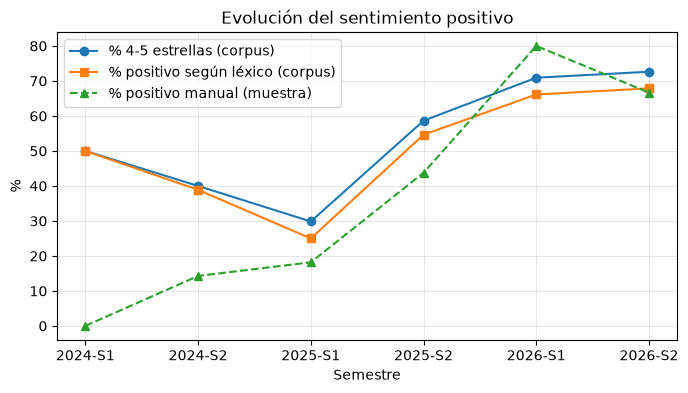

In [16]:
try:
    import matplotlib.pyplot as plt
    sem = [e_['semestre'] for e_ in r['evol_corpus']]
    plt.figure(figsize=(8, 4))
    plt.plot(sem, [e_['estrellas_pos']*100 for e_ in r['evol_corpus']], marker='o', label='% 4-5 estrellas (corpus)')
    plt.plot(sem, [e_['lexico_pos']*100 for e_ in r['evol_corpus']], marker='s', label='% positivo según léxico (corpus)')
    sm = {e_['semestre']: e_['pos']*100 for e_ in r['evol']}
    plt.plot(sem, [sm.get(s) for s in sem], marker='^', linestyle='--', label='% positivo manual (muestra)')
    plt.ylabel('%'); plt.xlabel('Semestre'); plt.legend(); plt.grid(alpha=.3); plt.title('Evolución del sentimiento positivo')
    os.makedirs('resultados', exist_ok=True)
    plt.savefig('resultados/fig_evolucion_semestre.png', dpi=200, bbox_inches='tight'); plt.show()
except ImportError:
    print('matplotlib no está instalado; en Colab sí.')

**Lectura.** El sentimiento positivo **no es estable**: el % de reseñas de 4-5★ baja a 30 % en 2025-S1 (IC 95 %: 25-36 %) y sube a 73 % en 2026-S2 (67-78 %); esos intervalos no se tocan, así que la diferencia entre periodos es real y no ruido. El léxico sigue a las estrellas de cerca: en los semestres con más de 50 reseñas nunca se separa más de 5 puntos, aunque se equivoque en reseñas sueltas (los errores individuales se compensan al agregar). La muestra manual cuenta la misma historia: 18 % de positivas en 2025-S1 y 80 % en 2026-S1; su baja a 67 % en 2026-S2 está dentro del ruido de 24 reseñas. **Qué semestres son poco fiables:** 2024-S1 tiene 2 reseñas en todo el corpus y solo 1 en la muestra manual; 2024-S2 tiene 90 y 7 en la muestra. No se afirma nada de la muestra manual antes de 2025, y 2026-S2 llega solo hasta el 21 de octubre.

### 4.7 ¿Qué se decía en cada semestre? Temas de queja

In [17]:
import re
cols = list(ac.TEMAS)
cab = '| Semestre | n | Estrellas (prom.) | ' + ' | '.join(cols) + ' |'
tem = ac.temas_por_semestre(corpus)
mostrar('**% de las reseñas que mencionan cada tema (todas las estrellas)**\n\n' + cab + '\n|' + '---|' * (3 + len(cols)) + '\n' +
        '\n'.join(f"| {t['semestre']} | {t['n']} | {t['estrellas_prom']:.2f} | " + ' | '.join(f"{t[c]*100:.0f} %" for c in cols) + ' |' for t in tem))
mostrar('**% de las reseñas de 1-2★ que mencionan cada tema**\n\n| Semestre | n (1-2★) | ' + ' | '.join(cols) + ' |\n|' + '---|' * (2 + len(cols)) + '\n' +
        '\n'.join(f"| {t['semestre']} | {t['n_1_2']} | " + ' | '.join(f"{t[c + ' (1-2★)']*100:.0f} %" for c in cols) + ' |' for t in tem))
# Ejemplos reales: las primeras reseñas del cambio a plástico y reseñas de producto roto
def ejemplos(tema, desde, hasta, n=4):
    pat = re.compile(ac.TEMAS[tema], re.I)
    ej = sorted((x for x in corpus if x['estrellas'] <= 2 and desde <= x['fecha'][:7] <= hasta and pat.search(x['titulo'] + ' ' + x['texto'].lower())),
                key=lambda x: (x['fecha'], x['id']))
    print(f"{tema}: {len(ej)} reseñas de 1-2★ entre {desde} y {hasta}. Ejemplos:")
    for x in ej[:n]: print(f"- {x['fecha']} {x['estrellas']}★ | {x['titulo']} | {x['texto'][:230]}")
ejemplos('Cambio a botella de plastico', '2025-04', '2025-07')
ejemplos('Producto roto o derrame', '2024-09', '2025-03')

**% de las reseñas que mencionan cada tema (todas las estrellas)**

| Semestre | n | Estrellas (prom.) | Producto roto o derrame | Cambio a botella de plastico | Sabor | Cambio de formula o producto | Envio o servicio | Efecto laxante | No funciona | Formula aguada o diluida |
|---|---|---|---|---|---|---|---|---|---|---|
| 2024-S1 | 2 | 3.50 | 0 % | 0 % | 50 % | 0 % | 0 % | 0 % | 0 % | 0 % |
| 2024-S2 | 90 | 2.80 | 23 % | 1 % | 54 % | 7 % | 17 % | 2 % | 6 % | 7 % |
| 2025-S1 | 268 | 2.38 | 16 % | 21 % | 61 % | 26 % | 15 % | 1 % | 7 % | 12 % |
| 2025-S2 | 324 | 3.52 | 2 % | 16 % | 62 % | 23 % | 11 % | 5 % | 4 % | 9 % |
| 2026-S1 | 313 | 3.92 | 1 % | 4 % | 43 % | 8 % | 6 % | 11 % | 5 % | 3 % |
| 2026-S2 | 274 | 4.00 | 0 % | 2 % | 37 % | 8 % | 5 % | 7 % | 3 % | 4 % |

**% de las reseñas de 1-2★ que mencionan cada tema**

| Semestre | n (1-2★) | Producto roto o derrame | Cambio a botella de plastico | Sabor | Cambio de formula o producto | Envio o servicio | Efecto laxante | No funciona | Formula aguada o diluida |
|---|---|---|---|---|---|---|---|---|---|
| 2024-S1 | 1 | 0 % | 0 % | 100 % | 0 % | 0 % | 0 % | 0 % | 0 % |
| 2024-S2 | 46 | 41 % | 2 % | 50 % | 9 % | 22 % | 2 % | 4 % | 9 % |
| 2025-S1 | 167 | 22 % | 29 % | 61 % | 32 % | 17 % | 1 % | 10 % | 17 % |
| 2025-S2 | 107 | 1 % | 41 % | 60 % | 44 % | 13 % | 3 % | 13 % | 20 % |
| 2026-S1 | 66 | 2 % | 15 % | 38 % | 21 % | 8 % | 6 % | 18 % | 12 % |
| 2026-S2 | 57 | 0 % | 7 % | 46 % | 19 % | 5 % | 12 % | 12 % | 14 % |

Cambio a botella de plastico: 65 reseñas de 1-2★ entre 2025-04 y 2025-07. Ejemplos:
- 2025-04-05 1★ | Misleading and not consistent | I received product on plastic bottle instead of glass.  This is my third time bying this product.  First 2 purchase came on glass bottle and each time they have a different taste.  Never again.
- 2025-04-16 1★ | I did not like the plastic bottles | I did not get the same benefits as i did on my first set of bottles because you all sent me the sour sop and black seed bitters in a plastic bottle thats not what i paid for i even felt different by taking this than when i receive
- 2025-05-07 1★ | The products differ from those on the original website. | I ordered from the official website, and the product arrived in glass bottles with professional packaging. However, the items I received from Amazon came in plastic bottles, and the seals on top were not secure. Additionally, the 
- 2025-05-11 1★ | Cheap packaging method! | First order came in a glass bottle 

**Lectura (hipótesis, no causa).** Aparecen dos historias distintas en el texto:

- **Producto roto o derramado en el envío:** 23 % de las reseñas de 2024-S2 y 16 % de las de 2025-S1 (22 % de las de 1-2★), frente a 0 % en 2026-S2. Son botellas de vidrio que llegan rotas ("broken glass bottle"). Parece un problema de empaque y envío que se resolvió.
- **Cambio a botella de plástico y de "fórmula":** hay una primera reseña en diciembre de 2024 y se multiplican desde abril-mayo de 2025: "I received product on plastic bottle instead of glass. This is my third time buying this product" (5 de abril de 2025) y reseñas como la del 24 de mayo de 2025, que cuenta que las botellas cambiaron de vidrio a plástico y que el producto sabe "soooo different". Las menciones del cambio a plástico son 21 % en 2025-S1 (29 % de las de 1-2★) y bajan a 2 % en 2026-S2; las de cambio de fórmula o producto, de 26 % a 8 %.

Mayo de 2025 es además el primer mes de 2025 que marca el semáforo (§4.8): la caída del sentimiento coincide con el aumento de esas quejas. Es una pista para la organización, no una prueba: las palabras clave son amplias, una mención no dice si fue la razón de la nota, y la base se descargó filtrando por estrellas. **Fecha aproximada del cambio, leída de las reseñas.** La primera mención del cambio a plástico es del 2024-12-02; antes de abril de 2025 hay 1 en total, en abril de 2025 hay 3, en mayo 26, en junio 28 y en septiembre 5. Eso ubica el cambio, de forma aproximada, entre finales de abril y mayo de 2025 (el comprador reseña unos días después de recibir). **La queja de "fórmula aguada" es anterior.** La primera mención de producto aguado, ralo o con fórmula distinta es del 2024-07-19; antes de abril de 2025 hay 9 en total y luego 1 en abril, 13 en mayo, 16 en junio y 3 en septiembre. Parece haber **dos problemas que se solapan**: quejas aisladas de producto aguado desde mediados de 2024 y una oleada en mayo-agosto de 2025 que coincide con el cambio a plástico. Para la decisión de revisar el lote o el proveedor (§1) eso importa: no es un solo evento. Las palabras clave son una aproximación, no un diagnóstico. Es la fecha que dicen los compradores, no la de la operación: el equipo no tiene las fechas reales del cambio de botella, de fórmula o de empaque y no están contrastadas.

### 4.8 Ejemplo de uso: el tablero mensual con semáforo

Caso concreto: cada mes el equipo mira el % de reseñas positivas según el léxico (sin entrenar nada nuevo). La regla tiene dos niveles y se mira cada mes con al menos 30 reseñas: **🔴 rojo** si el % positivo cae 10 puntos o más frente al promedio de los 3 meses anteriores (leer las reseñas negativas del mes y decidir); **🟡 amarillo** si cae entre 5 y 10 puntos (leerlas, sin actuar todavía). Se probó hacia atrás sobre todo el periodo (calibración más abajo).

In [18]:
mens = ac.mensual(corpus, ac.lexico_proyecto())
alertas = {a['mes']: a for a in ac.alertas(mens, caida=0.10, n_min=30)}
amarillas = {a['mes']: a for a in ac.alertas(mens, caida=0.05, n_min=30) if a['mes'] not in alertas}
def luz(m):
    if m['mes'] in alertas: return f"🔴 vs {alertas[m['mes']]['referencia']*100:.0f} % previo"
    if m['mes'] in amarillas: return f"🟡 vs {amarillas[m['mes']]['referencia']*100:.0f} % previo"
    return '· (n < 30)' if m['n'] < 30 else '🟢'
mostrar('| Mes | n | % 4-5★ | % positivo (léxico) | Semáforo |\n|---|---|---|---|---|\n' +
        '\n'.join(f"| {m['mes']} | {m['n']} | {m['estrellas_pos']*100:.0f} % | {m['lexico_pos']*100:.0f} % | " + luz(m) + ' |' for m in mens))
print('Meses en rojo:', sorted(alertas), '| en amarillo:', sorted(amarillas))

| Mes | n | % 4-5★ | % positivo (léxico) | Semáforo |
|---|---|---|---|---|
| 2024-06 | 2 | 50 % | 50 % | · (n < 30) |
| 2024-07 | 8 | 62 % | 25 % | · (n < 30) |
| 2024-08 | 12 | 25 % | 33 % | · (n < 30) |
| 2024-09 | 16 | 69 % | 62 % | · (n < 30) |
| 2024-10 | 7 | 29 % | 43 % | · (n < 30) |
| 2024-11 | 15 | 33 % | 33 % | · (n < 30) |
| 2024-12 | 32 | 31 % | 34 % | 🔴 vs 46 % previo |
| 2025-01 | 25 | 20 % | 16 % | · (n < 30) |
| 2025-02 | 28 | 57 % | 39 % | · (n < 30) |
| 2025-03 | 37 | 59 % | 43 % | 🟢 |
| 2025-04 | 34 | 35 % | 38 % | 🟢 |
| 2025-05 | 75 | 20 % | 17 % | 🔴 vs 40 % previo |
| 2025-06 | 69 | 14 % | 14 % | 🔴 vs 33 % previo |
| 2025-07 | 73 | 48 % | 42 % | 🟢 |
| 2025-08 | 84 | 67 % | 61 % | 🟢 |
| 2025-09 | 34 | 62 % | 56 % | 🟢 |
| 2025-10 | 32 | 53 % | 53 % | 🟢 |
| 2025-11 | 46 | 57 % | 50 % | 🟡 vs 57 % previo |
| 2025-12 | 55 | 64 % | 65 % | 🟢 |
| 2026-01 | 63 | 65 % | 60 % | 🟢 |
| 2026-02 | 56 | 75 % | 62 % | 🟢 |
| 2026-03 | 36 | 75 % | 72 % | 🟢 |
| 2026-04 | 45 | 87 % | 76 % | 🟢 |
| 2026-05 | 65 | 62 % | 63 % | 🟡 vs 70 % previo |
| 2026-06 | 48 | 69 % | 69 % | 🟢 |
| 2026-07 | 62 | 74 % | 74 % | 🟢 |
| 2026-08 | 73 | 78 % | 68 % | 🟢 |
| 2026-09 | 77 | 75 % | 70 % | 🟢 |
| 2026-10 | 62 | 61 % | 58 % | 🔴 vs 71 % previo |

Meses en rojo: ['2024-12', '2025-05', '2025-06', '2026-10'] | en amarillo: ['2025-11', '2026-05']


**Lectura.** La regla marca 4 meses: 2024-12, 2025-05, 2025-06, 2026-10. El primero de la crisis de 2025 es **2025-05**: el léxico leyó 17 % de positivas contra 40 % de los tres meses anteriores, con 75 reseñas; es decir, el tablero habría marcado la caída en el mes en que ocurrió y no al cierre del semestre. La regla también marca 2026-10 (58 % contra 71 %); es un mes incompleto (datos hasta el 21) y puede ser ruido: justo para eso sirve el semáforo, para disparar la lectura de las reseñas negativas de ese mes antes de decidir nada. El amarillo añade 2 meses (2025-11, 2026-05).

#### Calibración del umbral (prueba hacia atrás)

Como no hay una tolerancia de falsas alarmas dada por el cliente, el umbral se escogió con una prueba hacia atrás. **"Evento real"** = el % de 4-5★ (las estrellas, no el léxico) cae 10 puntos o más frente a los 3 meses anteriores. **Acierto** = el semáforo se enciende en un mes con evento; **falsa alarma** = se enciende sin evento; **perdido** = hubo evento y no se encendió.

In [19]:
bt = ac.backtest_alertas(mens)
mostrar('| Caída | n mín. | Meses evaluables | Eventos | Alertas | Aciertos | Falsas alarmas | Perdidos |\n|---|---|---|---|---|---|---|---|\n' +
        '\n'.join(f"| {f['caida']*100:.0f} pts | {f['n_min']} | {f['meses_evaluables']} | {f['eventos']} | {f['alertas']} | {f['aciertos']} | {f['falsas_alarmas']} | {f['perdidos']} |" for f in bt))

| Caída | n mín. | Meses evaluables | Eventos | Alertas | Aciertos | Falsas alarmas | Perdidos |
|---|---|---|---|---|---|---|---|
| 5 pts | 30 | 21 | 6 | 6 | 5 | 1 | 1 |
| 10 pts | 30 | 21 | 6 | 4 | 4 | 0 | 2 |
| 15 pts | 30 | 21 | 6 | 2 | 2 | 0 | 4 |
| 20 pts | 30 | 21 | 6 | 1 | 1 | 0 | 5 |
| 5 pts | 50 | 12 | 4 | 4 | 4 | 0 | 0 |
| 10 pts | 50 | 12 | 4 | 3 | 3 | 0 | 1 |
| 15 pts | 50 | 12 | 4 | 2 | 2 | 0 | 2 |
| 20 pts | 50 | 12 | 4 | 1 | 1 | 0 | 3 |

**Lectura.** Con 10 puntos y 30 reseñas el semáforo da 4 alertas en 21 meses evaluables, todas con evento real (0 falsas alarmas), pero pierde 2 de 6 eventos (2025-04, 2026-05). Bajar a 5 puntos recupera eventos (5 de 6) a cambio de 1 falsa alarma (2025-11). Como el error más caro es dejar pasar una queja (§1), se propone el **doble nivel**: rojo desde 10 puntos y amarillo desde 5, que en esta base son 6 meses con luz en 21 evaluables, es decir, unas 3 lecturas de reseñas cada 10 meses (rojos incluidos). Con 30 reseñas el margen de error de un porcentaje mensual es de unos 17 puntos, así que un solo mes amarillo no es prueba de nada: sirve para leer, no para decidir. **Limitaciones:** son pocos meses (21), el "evento real" sale de las mismas reseñas que alimentan el léxico y la base se descargó filtrando por estrellas, así que esto compara umbrales y no promete un desempeño futuro. Cuántas falsas alarmas al mes tolera el cliente sigue siendo un dato por confirmar con él.

### 4.9 Segunda lectura: léxico + KNN (y una tercera con Naive Bayes)

**Qué se hace.** El error caro es la queja leída como elogio (§1). El léxico es transparente pero deja pasar muchas; el KNN lee distinto. La **segunda lectura** marca como queja toda reseña que el léxico **o** el KNN marquen: el KNN revisa lo que el léxico dejó como positivo. La **tercera lectura** suma Naive Bayes. Se comparan también el voto de 2 de 3 y otras reglas simples. Son 8 reglas fijas, definidas antes de ver los resultados y **sin parámetros que ajustar**, para no sobreajustar con tan pocas negativas. Se miden en las mismas reseñas de prueba que la Prueba A (estrellas) y en las 85 de la Prueba B (ningún modelo entrenó con ellas; el léxico es el que no vio la muestra). Para cada regla: fp = queja leída como elogio, fn = falsa alarma, **% marcadas** = qué parte de las reseñas habría que leer, y un **costo** = c × fp + fn, donde c es cuántas veces pesa más dejar pasar una queja que una falsa alarma (c no se midió en dinero: es un juicio de quien decide. **Se fijó c = 5 como razón de trabajo** porque en §1 se dijo que la queja que se escapa cuesta reputación y tiempo y la falsa alarma solo tiempo; **se fijó después de ver las tablas**, así que es un grado de libertad más. Por eso se muestran también c = 1, 2 y 3 y el valor de c desde el cual cambia la conclusión).

In [20]:
costos = (1, 2, 3, 5)
yb_ = r['y_bin'][r['bin_ok']]; ok_ = r['bin_ok']; pb_ = r['punt']
tablas = {'Prueba A (estrellas)': ac.segunda_lectura(e['y_test'], e['punt']['Lexico (aprendido con el 80 %)'], e['punt']['KNN'], e['punt']['Naive Bayes']),
          'Prueba B (muestra manual, n = %d)' % len(yb_): ac.segunda_lectura(yb_, pb_['Lexico sin la muestra'][ok_], pb_['KNN con estrellas'][ok_], pb_['Naive Bayes con estrellas'][ok_])}
for titulo, filas_ in tablas.items():
    mostrar(f"**{titulo}: {filas_[0]['n']} reseñas**\n\n| Regla | fp (quejas escapadas) | fn (falsas alarmas) | Especificidad | Sensibilidad | Exactitud | % marcadas | " +
            ' | '.join(f'Costo c={c}' for c in costos) + ' |\n|' + '---|' * (7 + len(costos)) + '\n' +
            '\n'.join(f"| {f['regla']} | {f['fp']} | {f['fn']} | {f['especificidad']:.3f} | {f['sensibilidad']:.3f} | {f['exactitud']:.3f} | {f['pct_marcadas']*100:.0f} % | " +
                      ' | '.join(str(f[f'costo_c{c}']) for c in costos) + ' |' for f in filas_))

**Prueba A (estrellas): 235 reseñas**

| Regla | fp (quejas escapadas) | fn (falsas alarmas) | Especificidad | Sensibilidad | Exactitud | % marcadas | Costo c=1 | Costo c=2 | Costo c=3 | Costo c=5 |
|---|---|---|---|---|---|---|---|---|---|---|
| Léxico solo | 12 | 24 | 0.865 | 0.836 | 0.847 | 43 % | 36 | 48 | 60 | 84 |
| KNN solo | 6 | 15 | 0.933 | 0.897 | 0.911 | 42 % | 21 | 27 | 33 | 45 |
| Naive Bayes solo | 8 | 14 | 0.910 | 0.904 | 0.906 | 40 % | 22 | 30 | 38 | 54 |
| Léxico O KNN (segunda lectura) | 1 | 26 | 0.989 | 0.822 | 0.885 | 49 % | 27 | 28 | 29 | 31 |
| Léxico O KNN O NB (tercera lectura) | 1 | 27 | 0.989 | 0.815 | 0.881 | 49 % | 28 | 29 | 30 | 32 |
| Voto 2 de 3 | 6 | 14 | 0.933 | 0.904 | 0.915 | 41 % | 20 | 26 | 32 | 44 |
| KNN O NB | 4 | 17 | 0.955 | 0.884 | 0.911 | 43 % | 21 | 25 | 29 | 37 |
| Léxico Y KNN | 17 | 13 | 0.809 | 0.911 | 0.872 | 36 % | 30 | 47 | 64 | 98 |

**Prueba B (muestra manual, n = 85): 85 reseñas**

| Regla | fp (quejas escapadas) | fn (falsas alarmas) | Especificidad | Sensibilidad | Exactitud | % marcadas | Costo c=1 | Costo c=2 | Costo c=3 | Costo c=5 |
|---|---|---|---|---|---|---|---|---|---|---|
| Léxico solo | 2 | 4 | 0.939 | 0.923 | 0.929 | 41 % | 6 | 8 | 10 | 14 |
| KNN solo | 4 | 1 | 0.879 | 0.981 | 0.941 | 35 % | 5 | 9 | 13 | 21 |
| Naive Bayes solo | 5 | 1 | 0.848 | 0.981 | 0.929 | 34 % | 6 | 11 | 16 | 26 |
| Léxico O KNN (segunda lectura) | 0 | 4 | 1.000 | 0.923 | 0.953 | 44 % | 4 | 4 | 4 | 4 |
| Léxico O KNN O NB (tercera lectura) | 0 | 4 | 1.000 | 0.923 | 0.953 | 44 % | 4 | 4 | 4 | 4 |
| Voto 2 de 3 | 4 | 2 | 0.879 | 0.962 | 0.929 | 36 % | 6 | 10 | 14 | 22 |
| KNN O NB | 4 | 2 | 0.879 | 0.962 | 0.929 | 36 % | 6 | 10 | 14 | 22 |
| Léxico Y KNN | 6 | 1 | 0.818 | 0.981 | 0.918 | 33 % | 7 | 13 | 19 | 31 |

**Lectura.** **La segunda lectura reduce mucho las quejas que se escapan:** en la Prueba A pasa de 12 a 1 (0.865 a 0.989 de especificidad) y en la B de 2 a 0. Como la regla es una unión, atrapa todo lo que atrapaba el léxico más 11 quejas nuevas en A (y ninguna se pierde: 11 de 11 casos distintos van a su favor, p = 0.0005 en una prueba de signos exacta). En B son 2 casos, demasiado pocos para llamarlo significativo (p = 0.25), pero va en el mismo sentido. **El precio:** 2 falsas alarmas más en A (fn de 24 a 26) y hay que leer 49 % de las reseñas en lugar de 43 %.

**La tercera lectura no aporta:** sumar Naive Bayes no baja las quejas escapadas en A (quedan 1, igual que con la segunda) y suma 1 falsa(s) alarma(s) más, así que no se justifica un tercer modelo.

**¿Cuál regla gana?** Con la razón de trabajo c = 5, la segunda lectura es la de menor costo en A (31 contra 37 de la mejor otra regla, sin contar la tercera lectura, que es la misma con un lector más) y en B (4 contra 14). Pero depende de c. Menor costo en A: c = 1: Voto 2 de 3; c = 2: KNN O NB; c = 3: Léxico O KNN (segunda lectura) / KNN O NB; c = 5: Léxico O KNN (segunda lectura). Menor costo en B: c = 1: Léxico O KNN (segunda lectura) / Léxico O KNN O NB (tercera lectura); c = 2: Léxico O KNN (segunda lectura) / Léxico O KNN O NB (tercera lectura); c = 3: Léxico O KNN (segunda lectura) / Léxico O KNN O NB (tercera lectura); c = 5: Léxico O KNN (segunda lectura) / Léxico O KNN O NB (tercera lectura). **Umbral:** la segunda lectura cuesta lo mismo o menos que cualquier otra regla desde c = 3 en A (en c = 3 empata con KNN O NB, y gana cuando pesa más) y desde c = 0.75 en B. Si quien decide cree que dejar pasar una queja pesa menos de 3 veces una falsa alarma, el voto de 2 de 3 o KNN con Naive Bayes cuestan menos. **Límites:** la Prueba A usa las estrellas como etiqueta; B tiene solo 33 negativas; la segunda lectura se escogió entre 8 reglas mirando A y B, así que su ventaja puede estar algo inflada (por eso conviene reproducirla con las hojas de ampliación cuando se etiqueten).

### 4.10 Agrupamiento: ¿de qué hablan los compradores? (k-means)

**Qué se hace.** Un modelo de otra familia: en vez de leer el sentimiento, agrupa las reseñas por su texto. Se usa toda la base preparada (1271 reseñas): como no hay etiqueta que predecir no hay partición entrenamiento/prueba, y los grupos se juzgan con variables que **no entraron al modelo** (estrellas, semestre, compra verificada). **Preparación:** mismo texto limpio del KNN, TF-IDF de palabras y parejas, resumen a 30 ejes (SVD) y normalización. **Número de grupos:** para *k* de 2 a 8 se mide la inercia (codo), la silueta con distancia coseno y la estabilidad (qué tan iguales salen los grupos con 5 semillas distintas, índice de Rand ajustado: 1 = idénticos). La regla, fijada antes de mirar los grupos, es el primer *k* ≥ 3 cuya silueta es máximo local y cuya estabilidad es ≥ 0,9.

**Cómo se escogió k**

| k | Inercia | Silueta | Estabilidad | Grupo más pequeño |
|---|---|---|---|---|
| 2 | 978 | 0.114 | 0.99 | 335 |
| 3 ← | 925 | 0.133 | 0.99 | 322 |
| 4 | 890 | 0.115 | 0.89 | 184 |
| 5 | 856 | 0.141 | 0.61 | 125 |
| 6 | 824 | 0.152 | 0.74 | 115 |
| 7 | 798 | 0.164 | 0.75 | 104 |
| 8 | 772 | 0.178 | 0.64 | 45 |

**Perfil de cada grupo (variables que no entraron al modelo y, como ayuda de lectura, temas de queja)**

| Grupo | n | % | Estrellas | % 4-5★ | % verificada | Producto roto o derrame | Cambio a botella de plastico | Sabor | Cambio de formula o producto | Envio o servicio | Efecto laxante | No funciona | Formula aguada o diluida |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 0 | 416 | 33 % | 4.44 | 86 % | 97 % | 0 % | 0 % | 21 % | 3 % | 5 % | 3 % | 2 % | 0 % |
| 1 | 322 | 25 % | 1.72 | 9 % | 97 % | 19 % | 39 % | 52 % | 39 % | 16 % | 1 % | 7 % | 21 % |
| 2 | 533 | 42 % | 3.68 | 64 % | 92 % | 2 % | 1 % | 75 % | 11 % | 10 % | 11 % | 6 % | 3 % |

Grupo 0: great, work, good, product, love, great product, health, good product, really, work great
Grupo 1: bottle, plastic, not, product, glass, plastic bottle, order, glass bottle, water, come
Grupo 2: taste, bitter, take, but, not, feel, day, use, soursop, well


**Qué parte de cada semestre cae en cada grupo**

| Semestre | n | Grupo 0 | Grupo 1 | Grupo 2 |
|---|---|---|---|---|
| 2024-S1 | 2 | 0 % | 0 % | 100 % |
| 2024-S2 | 90 | 17 % | 31 % | 52 % |
| 2025-S1 | 268 | 12 % | 53 % | 35 % |
| 2025-S2 | 324 | 21 % | 29 % | 50 % |
| 2026-S1 | 313 | 45 % | 11 % | 44 % |
| 2026-S2 | 274 | 58 % | 9 % | 33 % |

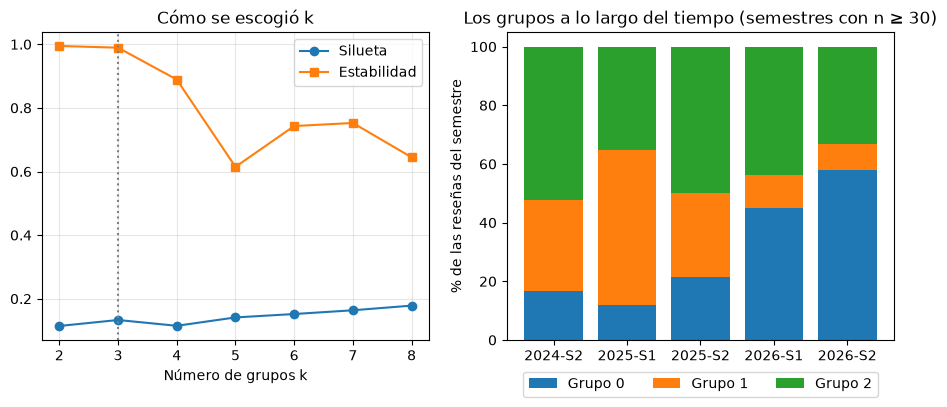

In [21]:
ag = ac.agrupar(prep)                                   # k-means sobre TF-IDF + SVD; escoge k con silueta y estabilidad
et_g = ag['etiquetas']
mostrar('**Cómo se escogió k**\n\n| k | Inercia | Silueta | Estabilidad | Grupo más pequeño |\n|---|---|---|---|---|\n' +
        '\n'.join(f"| {t['k']}{' ←' if t['k'] == ag['k'] else ''} | {t['inercia']:.0f} | {t['silueta']:.3f} | {t['estabilidad']:.2f} | {t['tam_min']} |" for t in ag['tabla']))
perfil = ac.perfil_grupos(prep, et_g); por_sem = ac.grupos_por_semestre(prep, et_g)
temas_g = [t for t in ac.TEMAS if t in perfil[0]]
mostrar('**Perfil de cada grupo (variables que no entraron al modelo y, como ayuda de lectura, temas de queja)**\n\n| Grupo | n | % | Estrellas | % 4-5★ | % verificada | ' + ' | '.join(temas_g) + ' |\n|' + '---|' * (6 + len(temas_g)) + '\n' +
        '\n'.join(f"| {p['grupo']} | {p['n']} | {p['pct']*100:.0f} % | {p['estrellas_prom']:.2f} | {p['pct_4_5']*100:.0f} % | {p['pct_verificada']*100:.0f} % | " + ' | '.join(f"{p[t]*100:.0f} %" for t in temas_g) + ' |' for p in perfil))
for g_, t_ in ag['top_terminos'].items(): print(f"Grupo {g_}: " + ', '.join(t_))
mostrar('**Qué parte de cada semestre cae en cada grupo**\n\n| Semestre | n | ' + ' | '.join(f'Grupo {g_}' for g_ in sorted(set(et_g.tolist()))) + ' |\n|---|---|' + '---|' * len(set(et_g.tolist())) + '\n' +
        '\n'.join(f"| {x['semestre']} | {x['n']} | " + ' | '.join(f"{x[f'grupo_{g_}']*100:.0f} %" for g_ in sorted(set(et_g.tolist()))) + ' |' for x in por_sem))
try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ks = [t['k'] for t in ag['tabla']]
    ax[0].plot(ks, [t['silueta'] for t in ag['tabla']], marker='o', label='Silueta'); ax[0].plot(ks, [t['estabilidad'] for t in ag['tabla']], marker='s', label='Estabilidad')
    ax[0].axvline(ag['k'], color='gray', linestyle=':'); ax[0].set_xlabel('Número de grupos k'); ax[0].legend(); ax[0].grid(alpha=.3); ax[0].set_title('Cómo se escogió k')
    sems = [x['semestre'] for x in por_sem if x['n'] >= 30]
    abajo = [0] * len(sems)
    for g_ in sorted(set(et_g.tolist())):
        v = [x[f'grupo_{g_}'] * 100 for x in por_sem if x['n'] >= 30]
        ax[1].bar(sems, v, bottom=abajo, label=f'Grupo {g_}'); abajo = [a_ + b_ for a_, b_ in zip(abajo, v)]
    ax[1].set_ylabel('% de las reseñas del semestre'); ax[1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=3); ax[1].set_title('Los grupos a lo largo del tiempo (semestres con n ≥ 30)')
    plt.savefig('resultados/fig_agrupamiento.png', dpi=200, bbox_inches='tight'); plt.show()
except ImportError:
    print('matplotlib no está instalado; en Colab sí.')

**Lectura.** La regla escoge **k = 3** (silueta 0.133, estabilidad 0.99). La silueta es baja en todos los *k* (el texto de las reseñas no se separa en grupos nítidos: hablan de lo mismo con matices) y sube sin parar con *k* a costa de grupos pequeños e inestables, así que el codo no es claro; por eso se exige también estabilidad. Los tres grupos:

- **Grupo 0, elogio general** (33 %): palabras como great, work, good, product, love; 4.44★ de promedio y 86 % de 4-5★.
- **Grupo 1, queja de producto** (25 %): palabras como bottle, plastic, not, product, glass; 1.72★ y solo 9 % de 4-5★. 39 % menciona el cambio a plástico, 21 % la fórmula aguada y 19 % producto roto o derramado.
- **Grupo 2, sabor y cómo me siento** (42 %): palabras como taste, bitter, take, but, not; 3.68★. 75 % habla del sabor: es el tema de conversación, no necesariamente una queja (64 % da 4-5★).

**Lo que aporta frente a los otros modelos:** el grupo de queja de producto pasa de 31 % de las reseñas en 2024-S2 a **53 % en 2025-S1** y baja a 9 % en 2026-S2. Cuenta **la misma historia que el semáforo y los temas de §4.7, pero sin usar estrellas ni palabras clave para armar los grupos**, lo que es coherente con que la crisis de 2025 fue una queja de producto (botella, envío y fórmula) y no solo un mal humor general, aunque no lo prueba. **Límites:** los grupos son una descripción, no una prueba de causa; la silueta baja indica fronteras difusas (una reseña puede hablar de sabor y de plástico a la vez); los temas de queja del perfil se calculan con palabras clave del mismo texto, así que no son una validación independiente; y los nombres de los grupos los pone el equipo al leerlos.

### Exportar tablas para el documento y las diapositivas

In [22]:
import csv
os.makedirs('resultados', exist_ok=True)
def guardar_csv(nombre, filas_csv):
    with open(f'resultados/{nombre}', 'w', newline='', encoding='utf-8') as fh:
        w = csv.DictWriter(fh, fieldnames=list(filas_csv[0])); w.writeheader(); w.writerows(filas_csv)
for nombre, res in (('metricas_prueba_A_estrellas.csv', e['prueba']), ('metricas_prueba_B_manual_20.csv', r['prueba']), ('metricas_prueba_B_manual_completa.csv', r['todas'])):
    guardar_csv(nombre, [{'modelo': m, **v} for m, v in res.items()])
guardar_csv('evolucion_muestra_manual.csv', r['evol'])
guardar_csv('evolucion_corpus.csv', r['evol_corpus'])
guardar_csv('temas_por_semestre.csv', tem)
guardar_csv('tablero_mensual.csv', [{**m, 'rojo': m['mes'] in alertas, 'amarillo': m['mes'] in amarillas} for m in mens])
guardar_csv('calibracion_semaforo.csv', bt)
guardar_csv('agrupamiento_k.csv', ag['tabla']); guardar_csv('agrupamiento_perfil.csv', perfil); guardar_csv('agrupamiento_por_semestre.csv', por_sem)
for _t, _f in tablas.items(): guardar_csv('segunda_lectura_' + ('A' if _t.startswith('Prueba A') else 'B') + '.csv', _f)
guardar_csv('desacuerdos_lexico.csv', [dict(manual=c[0], lexico=c[1], puntaje=c[2], titulo=c[3], texto=c[4]) for c in casos])
print('Guardado en resultados/:', sorted(os.listdir('resultados')))

Guardado en resultados/: ['agrupamiento_k.csv', 'agrupamiento_perfil.csv', 'agrupamiento_por_semestre.csv', 'calibracion_semaforo.csv', 'desacuerdos_lexico.csv', 'evolucion_corpus.csv', 'evolucion_muestra_manual.csv', 'fig_agrupamiento.png', 'fig_evolucion_semestre.png', 'metricas_muestra_completa.csv', 'metricas_prueba_20.csv', 'metricas_prueba_A_estrellas.csv', 'metricas_prueba_B_manual_20.csv', 'metricas_prueba_B_manual_completa.csv', 'segunda_lectura_A.csv', 'segunda_lectura_B.csv', 'tablero_mensual.csv', 'temas_por_semestre.csv']


## 5. Recomendaciones para la decisión

1. **Instalar un tablero mensual de sentimiento con el léxico** (no necesita entrenar nada, es transparente y sigue a las estrellas a menos de 5 puntos por semestre) y la regla de semáforo de dos niveles de §4.8. Cuando el semáforo se pone amarillo o rojo, **leer las reseñas negativas de ese mes antes de actuar**.
2. **Para decidir a qué quejas responder o reembolsar, usar una segunda lectura (léxico O KNN).** El error que más cuesta es dejar pasar una queja. La segunda lectura baja las quejas escapadas de 12 a 1 en la Prueba A y de 2 a 0 en la B, a cambio de 2 falsas alarmas más en A y de leer 49 % de las reseñas en lugar de 43 % (§4.9). Un tercer modelo (Naive Bayes) no mejora. La conclusión es más firme en A (estrellas) que en B (solo 33 negativas) y depende de cuánto más caro sea dejar pasar una queja que una falsa alarma: con la razón de trabajo c = 5 (una queja escapada pesa 5 falsas alarmas, fijada después de ver las tablas) la segunda lectura es la de menor costo, y lo es desde c = 3; si el cliente la juzga menos grave que eso, el voto de 2 de 3 cuesta menos. Ese peso hay que confirmarlo con el cliente.
3. **Contrastar las dos hipótesis de §4.7 con lo que realmente cambió en la operación:** los daños en el envío (ya casi no aparecen) y el cambio de botella y de fórmula. Si se confirman, el costo se puede estimar con la caída de 30 % frente a 73 % de reseñas positivas. El equipo no tiene esas fechas: hay que pedirlas a quien opera el producto antes de decidir.
4. **Vigilar también de qué se habla, no solo cuánto gusta:** el agrupamiento de §4.10 separa un grupo de queja de producto (botella, envío, fórmula) que llegó a 53 % de las reseñas en 2025-S1. Seguir su peso por mes complementa al semáforo de sentimiento: avisa **qué** está fallando, que es lo que hace falta para decidir si revisar el lote o al proveedor.
5. **No usar estos modelos** para reseñas en otro idioma, para clasificar Neutro ni como único criterio ante una crisis: el léxico lee mal lo mixto y lo irónico (§4.5).

**Qué se mediría después:** el % positivo por mes con intervalo de confianza, las alertas que fueron falsas alarmas, y cuántas de las reseñas negativas de un mes marcado terminan en una acción concreta. **Riesgo de confiar en el modelo:** una caída leída como falsa alarma por exceso de confianza; por eso la regla manda a leer reseñas y no a decidir sola.

## 6. Limitaciones y trabajo futuro

- **Tamaño de la muestra manual (100; 17 en la prueba).** Los intervalos son muy anchos: no se puede ordenar a los modelos con ella (§4.2). Efecto: la comparación se apoya en la prueba A (estrellas). Trabajo futuro: etiquetar las 400 reseñas de las hojas de ampliación y repetir (el notebook las incluye solas cuando estén completas).
- **Neutro fuera de las métricas binarias.** Son 15 de 100; los modelos binarios no tienen cómo decirlas y el léxico casi nunca las acierta. Efecto: el acierto real sobre texto ambiguo es menor que el reportado.
- **La etiqueta de la prueba A es la nota en estrellas,** que no siempre coincide con el texto. Efecto: algunos errores de modelo son en realidad errores de la etiqueta.
- **Idioma:** todo en inglés; una reseña en español queda sin leer. Efecto: no sirve tal cual para otros mercados.
- **Periodo y fuente.** Unos 2,4 años, un producto, un canal y reseñas descargadas por filtros de estrellas; los semestres 2024-S1 y 2024-S2 tienen muy pocas reseñas y 2026-S2 es parcial. Efecto: la evolución se puede describir pero no pronosticar; el profesor aprobó usar este período.
- **Agrupamiento (§4.10):** la silueta es baja (los grupos se solapan) y los nombres los pone quien los lee. Efecto: sirve para describir de qué se habla, no para asignar con certeza cada reseña a un tema.
- **Qué no hace el modelo:** no explica por qué cambia el sentimiento; las pistas de §4.7 son palabras clave, no causas.